# Render the Dreadnoughts Using the Game Data

In [116]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:70% !important; }</style>"))

### Load the Source Code

In [117]:
source_file = "uridium-listing.txt"
input_file = open(source_file,'r')
source_lines = [l.split('\t') for l in input_file.readlines()]

segments = []
segment = "game_logic"
segment_bytes = []
segment_source_lines = []
for l in source_lines:
    if len(l) == 1:
        if "Processing file" in l[0]:
            if segment_bytes:
                segments += [(segment, segment_bytes,segment_source_lines)]
            segment_bytes = []
            segment_source_lines = []
            segment = l[0].split('/')[1].strip().replace('.asm','')
        if "Return to file" in l[0]:
            if segment_bytes:
                segments += [(segment, segment_bytes,segment_source_lines)]
            segment_bytes = []
            segment_source_lines = []
            segment = "game_logic"
        continue
    if len(l) != 4:
        continue
    address, bytes_string, assembly_line, source_line = l
    segment_bytes += bytes_string.split()
    segment_source_lines += [source_line]
segments += [(segment, segment_bytes,segment_source_lines)]

In [118]:
resize = lambda img,factor: img.resize((int(img.width * factor), int(img.height * factor)), Image.NEAREST)

In [119]:
for s,bs,_ in segments:
    print(s, len(bs))

game_logic 3263
game_data 3204
structure_data 1896
game_logic 946
level_data 8196
surface1_charset 1024
surface2_charset 1024
surface3_charset 1024
game_logic 139
dropship_sprites 768
explosion_sprites 3328
ship_sprites 3062
enemy_sprites 2048
charset 3072
game_logic 384


In [120]:
1024+1024+1024+8196+1896

13164

In [145]:
sum([len(bs) for s,bs,_ in segments if "sprites" in s])

9206

In [121]:
segment_names = set([s for s,_,_ in segments])
segment_colors = {n:i+3 for i,n in enumerate(segment_names)}

In [122]:
!mkdir -p source_map

### Game Logic 1

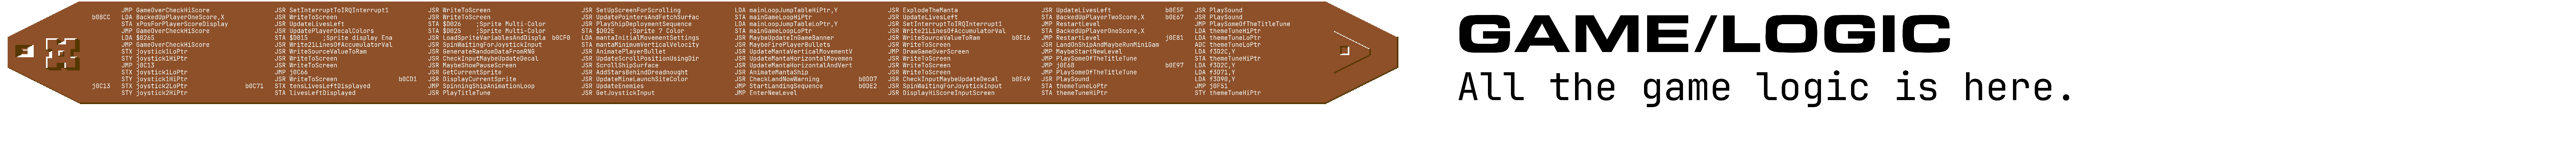

In [123]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 0

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = segment_colors[segment_name]
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add the source text to the surface layer
"""
x,y = 600,40
num_lines = 13
for f in range(100,200,num_lines):
    src_lines = '\n'.join([x.rstrip()[:40] for x in segment_source_lines[f:f + num_lines]])
    src_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 40)
    draw = ImageDraw.Draw(img)
    draw.text((x, y), src_lines, font=src_fnt, fill="white")
    x+=1000

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (8700,200), mask=back1_png)
img.paste(back2_png, (8710,270), mask=back2_png)

"""
Draw the label
"""
label_text = "GAME/LOGIC"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((9500, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
All the game logic is here.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((9500, 400), caption_text, font=caption_fnt, fill="black")

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/game_logic.png")
img

### Game Data

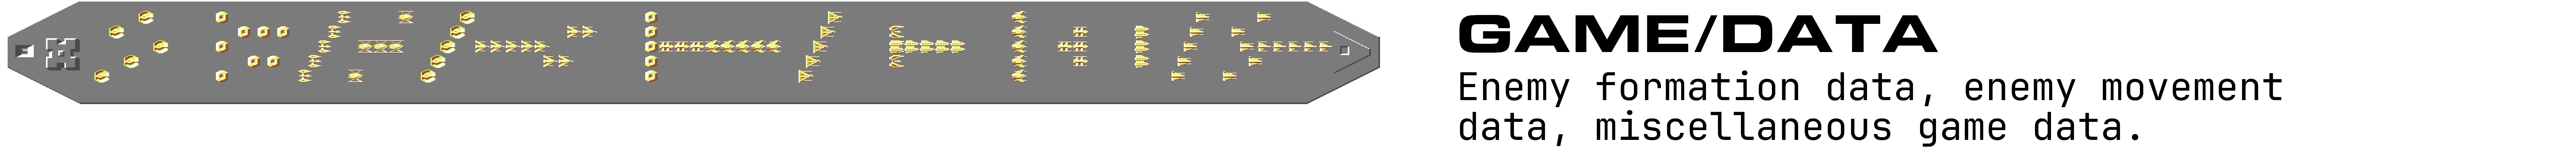

In [124]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 1

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = segment_colors[segment_name]
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (8700,200), mask=back1_png)
img.paste(back2_png, (8710,270), mask=back2_png)

"""
Draw the label
"""
label_text = "GAME/DATA"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((9500, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Enemy formation data, enemy movement\ndata, miscellaneous game data.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((9500, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
x,y = 600,40
x_orig = x
for i,f in enumerate(range(26,46)):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"formations/1_formation_{f}.png")
    decor_png = resize(decor_png, 2)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=400

"""
x_orig = x
y = 40
for i,f in enumerate(range(6,16)):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"formations/3_formation_{f}.png")
    decor_png = resize(decor_png, 2)
    img.paste(decor_png, (x,y), mask=decor_png)
    if i == 14:
        y+= 300
        x = x_orig - 300
    x+=300

x_orig = x
y = 40
for i,f in enumerate(range(6,19)):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"formation_movement/formations/formation_movements_{f}.png")
    img.paste(decor_png, (x,y), mask=decor_png)
    if i == 6:
        y+= 300
        x = x_orig - 700
    x+=700
"""

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/game_data.png")
img

### Structure Data

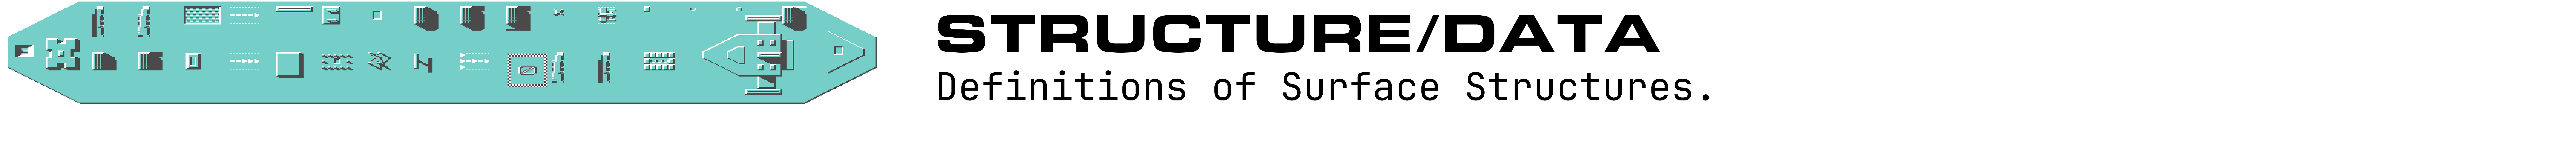

In [125]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 2

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = segment_colors[segment_name]

open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (5400,200), mask=back1_png)
img.paste(back2_png, (5410,270), mask=back2_png)

"""
Draw the label
"""
label_text = "STRUCTURE/DATA"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((6100, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Definitions of Surface Structures.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((6100, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
from itertools import chain
x,y = 600,40
x_orig = x
for i,f in enumerate(chain(range(13,30), range(80,85),range(103,107), [14,13,144])):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"surface_structures/{level}_{f}.png")
    img.paste(decor_png, (x,y), mask=decor_png)
    if i > 0 and i % 15 == 0:
        y+= 300
        x = 300
    x+=300
    
decor_png = Image.open(f"surface_structures/{level}_147.png")
img.paste(decor_png, (4580,100), mask=decor_png)

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/structure_data.png")
img

### Level Data - Left Half

512


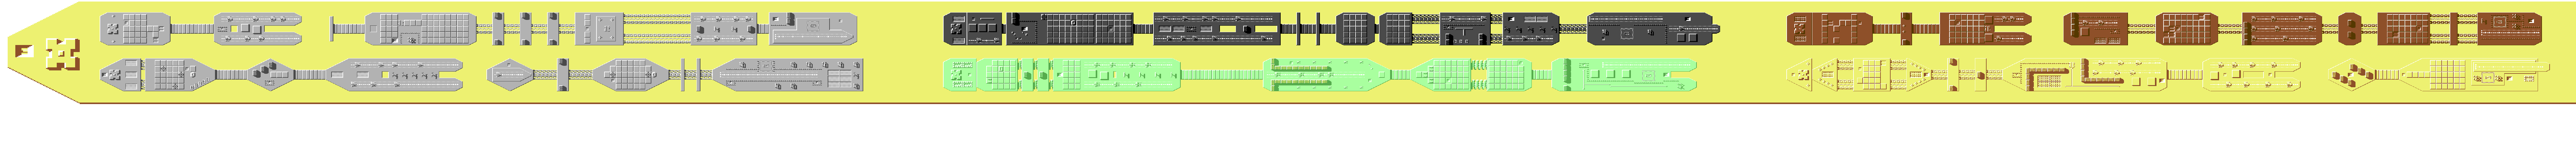

In [126]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 4

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)
print(num_lines)

"""
Create the base layer
"""
level = 6
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")

"""
Add front section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Add mid section
"""
for i in range(0, 410):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width


"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

"""
Add the dreadnoughts to the surface layer
"""
from itertools import chain
x,y = 600,80
x_orig = x
for f in range(1,7):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"surfaces_raw/{f}.png")
    decor_png = resize(decor_png, 1.6)
    img.paste(decor_png, (x,y), mask=decor_png)
    if f > 1 and f % 3 == 0:
        y+= 300
        x = 600
        continue
    x+=5500
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/level_data_1.png")
img

### Level Data - Right Half

512


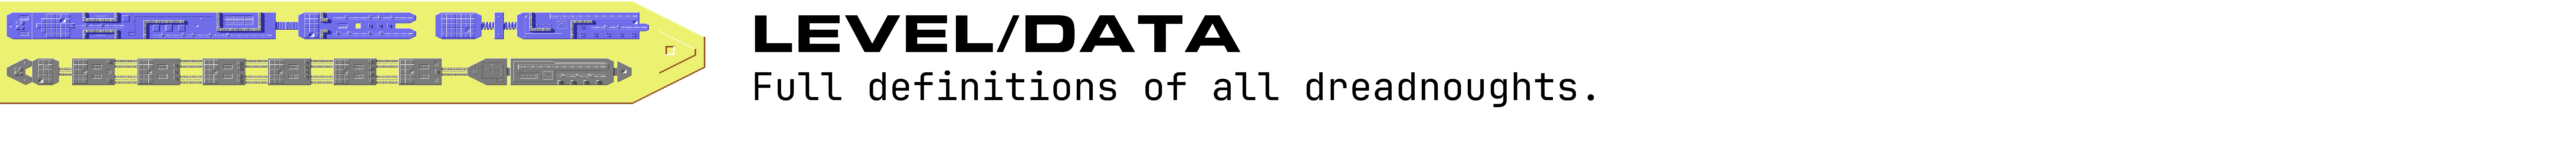

In [127]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 4

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)
print(num_lines)
"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


for i in range(410, 513):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (4300,200), mask=back1_png)
img.paste(back2_png, (4310,270), mask=back2_png)

"""
Draw the label
"""
label_text = "LEVEL/DATA"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((4900, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Full definitions of all dreadnoughts.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((4900
           , 400), caption_text, font=caption_fnt, fill="black")

"""
Add the dreadnoughts to the surface layer
"""
x,y = 0,80
x_orig = x
for f in range(9,11):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"surfaces_raw/{f}.png")
    decor_png = resize(decor_png, 1.3)
    img.paste(decor_png, (x,y), mask=decor_png)
    if f > 1 and f % 1 == 0:
        y+= 300
        x = 0
        continue
    x+=3500
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/level_data_2.png")
img

### Surface 1 Charset

In [128]:
level_charsets = [0,2,0,2,0,1,2,1,0,1,2,0,2,1,0,2]

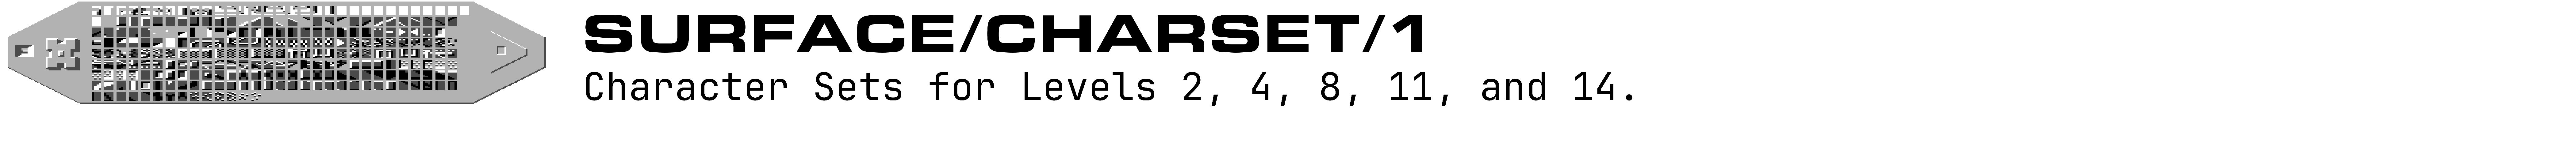

In [129]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 5

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 4
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (3200,200), mask=back1_png)
img.paste(back2_png, (3210,270), mask=back2_png)

"""
Draw the label
"""
label_text = "SURFACE/CHARSET/1"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((3800, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
level_charsets = [2,0,2,0,1,2,1,0,1,2,0,2,1,0,2]
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Character Sets for Levels 2, 4, 8, 11, and 14.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((3800, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
from itertools import chain
x,y = 600,40
x_orig = x
for f in range(0, 0xFF):
    f_hex = f"{f:02X}"
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"surface_characters/2_{f_hex}.png")
    decor_png = decor_png.resize((int(decor_png.width * 0.5), int(decor_png.height * 0.5)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if f > 0 and f % 30 == 0:
        y+= 70
        x = 600
        continue
    x+=80
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/surface_charset_1.png")
img

### Surface Charset 2

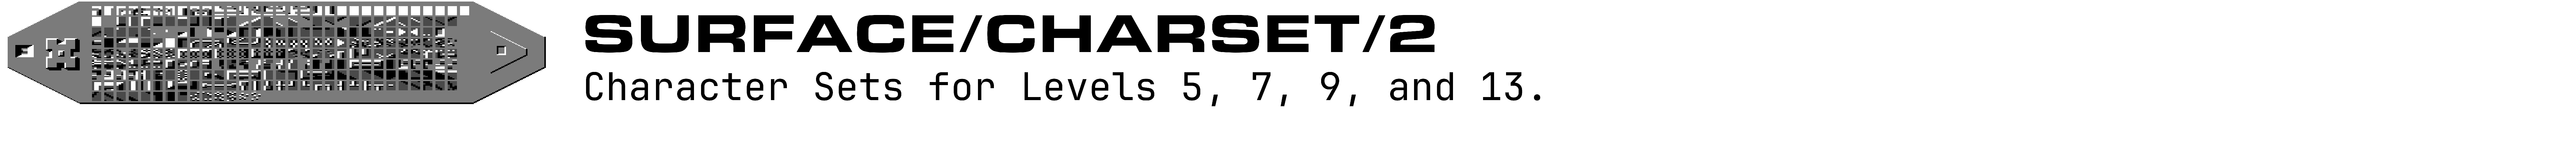

In [130]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 6

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 8
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (3200,200), mask=back1_png)
img.paste(back2_png, (3210,270), mask=back2_png)

"""
Draw the label
"""
label_text = "SURFACE/CHARSET/2"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((3800, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
level_charsets = [2,0,2,0,1,2,1,0,1,2,0,2,1,0,2]
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Character Sets for Levels 5, 7, 9, and 13.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((3800, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
from itertools import chain
x,y = 600,40
x_orig = x
for f in range(0, 0xFF):
    f_hex = f"{f:02X}"
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"surface_characters/13_{f_hex}.png")
    decor_png = decor_png.resize((int(decor_png.width * 0.5), int(decor_png.height * 0.5)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if f > 0 and f % 30 == 0:
        y+= 70
        x = 600
        continue
    x+=80
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/surface_charset_2.png")
img

### Surface Charset 3

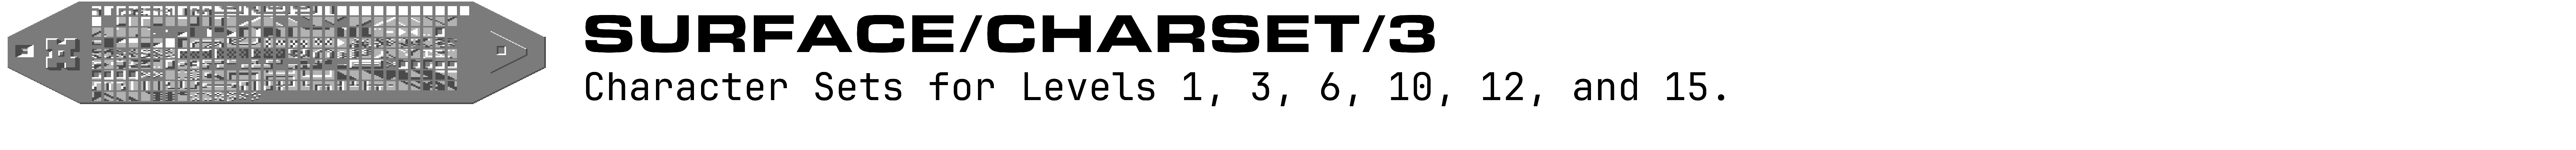

In [131]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 7

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 10
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (3200,200), mask=back1_png)
img.paste(back2_png, (3210,270), mask=back2_png)

"""
Draw the label
"""
label_text = "SURFACE/CHARSET/3"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((3800, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
level_charsets = [2,0,2,0,1,2,1,0,1,2,0,2,1,0,2]
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Character Sets for Levels 1, 3, 6, 10, 12, and 15.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((3800, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
from itertools import chain
x,y = 600,40
x_orig = x
for f in range(0, 0xFF):
    f_hex = f"{f:02X}"
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"surface_characters/1_{f_hex}.png")
    decor_png = decor_png.resize((int(decor_png.width * 0.5), int(decor_png.height * 0.5)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if f > 0 and f % 30 == 0:
        y+= 70
        x = 600
        continue
    x+=80
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/surface_charset_3.png")
img

### Dropship Sprites

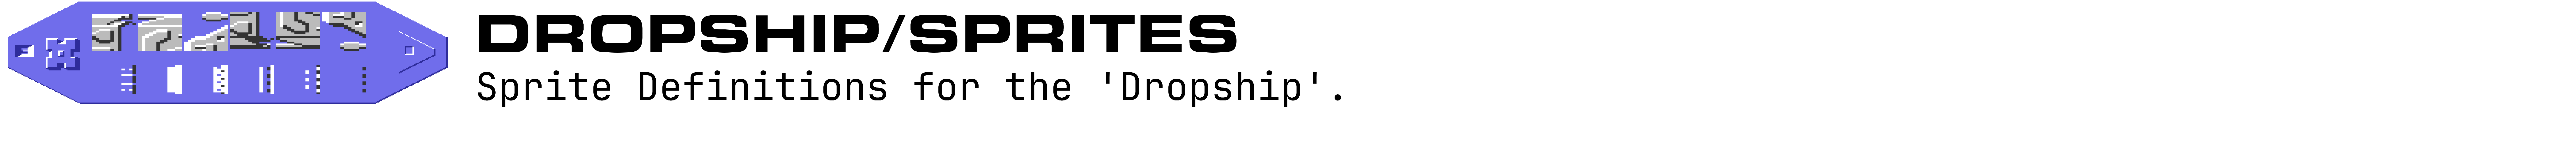

In [132]:
from PIL import Image, ImageFont,ImageDraw
"""
game_logic 3263
game_data 3204
structure_data 1896
game_logic 946
level_data 8196
surface1_charset 1024
surface2_charset 1024
surface3_charset 1024
game_logic 139
dropship_sprites 768
explosion_sprites 3328
ship_sprites 3062
enemy_sprites 2048
charset 3072
game_logic 384
"""

SEGMENT_NUMBER = 9

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = segment_colors[segment_name]
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (2600,200), mask=back1_png)
img.paste(back2_png, (2610,270), mask=back2_png)

"""
Draw the label
"""
label_text = "DROPSHIP/SPRITES"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((3100, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Sprite Definitions for the 'Dropship'.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((3100, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the sprites
"""
from itertools import chain
x,y = 600,80
x_orig = x
for f in range(0, 12):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f"dropship_sprites/DROPSHIP_{f}.png")
    decor_png = resize(decor_png,12)
    img.paste(decor_png, (x,y), mask=decor_png)
    if f == 5:
        y+= 320
        x = 600
        continue
    x+=300
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/dropship_sprites.png")
img

###  Explosion Sprites

In [133]:
ls manta_explosion_sprites/1*

manta_explosion_sprites/1_EXPLOSION_MAJOR10.png
manta_explosion_sprites/1_EXPLOSION_MAJOR11.png
manta_explosion_sprites/1_EXPLOSION_MAJOR1.png
manta_explosion_sprites/1_EXPLOSION_MAJOR2.png
manta_explosion_sprites/1_EXPLOSION_MAJOR3.png
manta_explosion_sprites/1_EXPLOSION_MAJOR4.png
manta_explosion_sprites/1_EXPLOSION_MAJOR5.png
manta_explosion_sprites/1_EXPLOSION_MAJOR6.png
manta_explosion_sprites/1_EXPLOSION_MAJOR7.png
manta_explosion_sprites/1_EXPLOSION_MAJOR8.png
manta_explosion_sprites/1_EXPLOSION_MAJOR9.png


In [134]:
explosion_sprites = """meanie_explosion_sprites/1_BULLET_5.png
meanie_explosion_sprites/1_BULLET_NARROW.png
meanie_explosion_sprites/1_BULLET_SINGLE.png
meanie_explosion_sprites/1_BULLET_VERYNARROW.png
meanie_explosion_sprites/1_BULLET_WIDE.png
meanie_explosion_sprites/1_EXPLOSION_1.png
meanie_explosion_sprites/1_EXPLOSION_2.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR10.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR11.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR1.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR2.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR3.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR4.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR5.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR6.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR7.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR8.png
meanie_explosion_sprites/1_EXPLOSION_MAJOR9.png
meanie_explosion_sprites/1_MEANIE_EXPLOSION_1.png
meanie_explosion_sprites/1_MEANIE_EXPLOSION_2.png
meanie_explosion_sprites/1_MEANIE_EXPLOSION_3.png
meanie_explosion_sprites/1_MEANIE_EXPLOSION_4.png
meanie_explosion_sprites/1_MEANIE_EXPLOSION_5.png
meanie_explosion_sprites/1_MEANIE_SECONDARY_1.png
meanie_explosion_sprites/1_MEANIE_SECONDARY_2.png
meanie_explosion_sprites/1_MEANIE_SECONDARY_3.png
meanie_explosion_sprites/1_MEANIE_SECONDARY_4.png
meanie_explosion_sprites/1_MEANIE_SECONDARY_5.png
manta_explosion_sprites/1_EXPLOSION_MAJOR10.png
manta_explosion_sprites/1_EXPLOSION_MAJOR11.png
manta_explosion_sprites/1_EXPLOSION_MAJOR1.png
manta_explosion_sprites/1_EXPLOSION_MAJOR2.png
manta_explosion_sprites/1_EXPLOSION_MAJOR3.png
manta_explosion_sprites/1_EXPLOSION_MAJOR4.png
manta_explosion_sprites/1_EXPLOSION_MAJOR5.png
manta_explosion_sprites/1_EXPLOSION_MAJOR6.png
manta_explosion_sprites/1_EXPLOSION_MAJOR7.png
manta_explosion_sprites/1_EXPLOSION_MAJOR8.png
manta_explosion_sprites/1_EXPLOSION_MAJOR9.png
""".split('\n')[:-1]

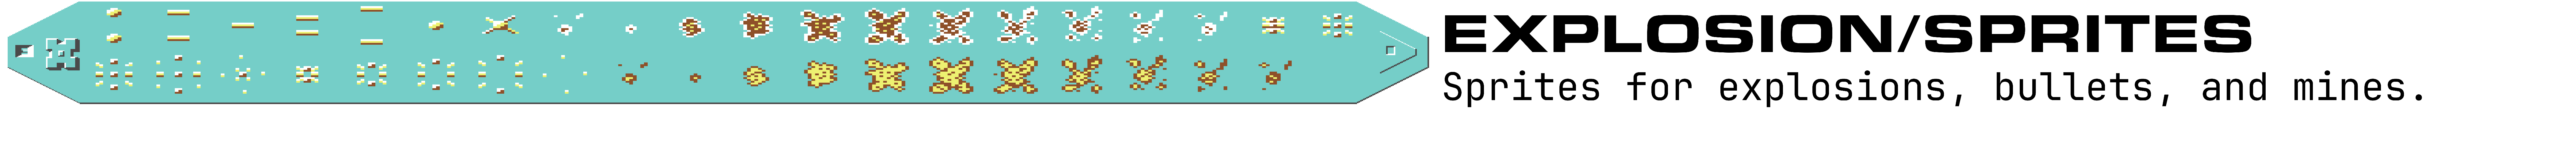

In [135]:
#### from PIL import Image, ImageFont,ImageDraw
"""
game_logic 3263
game_data 3204
structure_data 1896
game_logic 946
level_data 8196
surface1_charset 1024
surface2_charset 1024
surface3_charset 1024
game_logic 139
dropship_sprites 768
explosion_sprites 3328
ship_sprites 3062
enemy_sprites 2048
charset 3072
game_logic 384
"""

SEGMENT_NUMBER = 10

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 7
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (9000,200), mask=back1_png)
img.paste(back2_png, (9010,270), mask=back2_png)

"""
Draw the label
"""
label_text = "EXPLOSION/SPRITES"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((9400, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Sprites for explosions, bullets, and mines.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((9400, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the sprites
"""
from itertools import chain
x,y = 600,40
x_orig = x
for i,f in enumerate(explosion_sprites):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f)
    #decor_png = decor_png.resize((int(decor_png.width * 10), int(decor_png.height * 10)), Image.NEAREST)
    decor_png = decor_png.resize((int(decor_png.width * 1.2), int(decor_png.height * 1.2)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if i+1 > 1 and (i+1) % 20 == 0:
        y+= 320
        x = 600
        continue
    x+=420
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/explosion_sprites.png")
img

### Ship Sprites

In [136]:
manta_sprites = """manta_spin_diagrams/MANTA1.png
manta_spin_diagrams/MANTA_2.png
manta_spin_diagrams/MANTA_FLIP_0.png
manta_spin_diagrams/MANTA_FLIP_10.png
manta_spin_diagrams/MANTA_FLIP_11.png
manta_spin_diagrams/MANTA_FLIP_12.png
manta_spin_diagrams/MANTA_FLIP_13.png
manta_spin_diagrams/MANTA_FLIP_1.png
manta_spin_diagrams/MANTA_FLIP_2.png
manta_spin_diagrams/MANTA_FLIP_3.png
manta_spin_diagrams/MANTA_FLIP_4.png
manta_spin_diagrams/MANTA_FLIP_5.png
manta_spin_diagrams/MANTA_FLIP_6.png
manta_spin_diagrams/MANTA_FLIP_7.png
manta_spin_diagrams/MANTA_FLIP_8.png
manta_spin_diagrams/MANTA_FLIP_9.png
manta_spin_diagrams/MANTA_LEFT_0.png
manta_spin_diagrams/MANTA_LEFT_10.png
manta_spin_diagrams/MANTA_LEFT_11.png
manta_spin_diagrams/MANTA_LEFT_12.png
manta_spin_diagrams/MANTA_LEFT_13.png
manta_spin_diagrams/MANTA_LEFT_14.png
manta_spin_diagrams/MANTA_LEFT_15.png
manta_spin_diagrams/MANTA_LEFT_1.png
manta_spin_diagrams/MANTA_LEFT_2.png
manta_spin_diagrams/MANTA_LEFT_3.png
manta_spin_diagrams/MANTA_LEFT_4.png
manta_spin_diagrams/MANTA_LEFT_5.png
manta_spin_diagrams/MANTA_LEFT_6.png
manta_spin_diagrams/MANTA_LEFT_7.png
manta_spin_diagrams/MANTA_LEFT_8.png
manta_spin_diagrams/MANTA_LEFT_9.png
manta_spin_diagrams/MANTA.png
manta_spin_diagrams/MANTA_RIGHT_10.png
manta_spin_diagrams/MANTA_RIGHT_11.png
manta_spin_diagrams/MANTA_RIGHT_12.png
manta_spin_diagrams/MANTA_RIGHT_13.png
manta_spin_diagrams/MANTA_RIGHT_14.png
manta_spin_diagrams/MANTA_RIGHT_15.png
manta_spin_diagrams/MANTA_RIGHT_3.png
manta_spin_diagrams/MANTA_RIGHT_4.png
manta_spin_diagrams/MANTA_RIGHT_5.png
manta_spin_diagrams/MANTA_RIGHT_6.png
manta_spin_diagrams/MANTA_RIGHT_7.png
manta_spin_diagrams/MANTA_RIGHT_8.png
manta_spin_diagrams/MANTA_RIGHT_9.png
""".split('\n')[:-1]

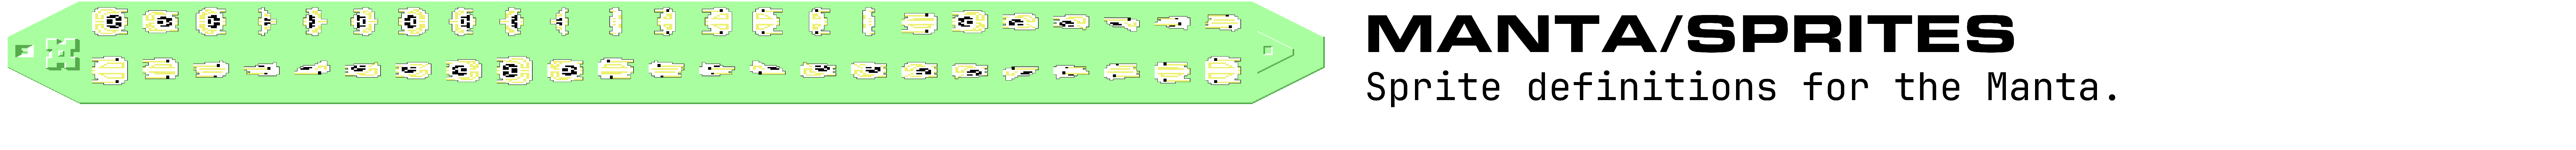

In [137]:
#### from PIL import Image, ImageFont,ImageDraw
"""
game_logic 3263
game_data 3204
structure_data 1896
game_logic 946
level_data 8196
surface1_charset 1024
surface2_charset 1024
surface3_charset 1024
game_logic 139
dropship_sprites 768
explosion_sprites 3328
ship_sprites 3062
enemy_sprites 2048
charset 3072
game_logic 384
"""

SEGMENT_NUMBER = 11

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 5
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (8200,200), mask=back1_png)
img.paste(back2_png, (8210,270), mask=back2_png)

"""
Draw the label
"""
label_text = "MANTA/SPRITES"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((8900, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Sprite definitions for the Manta.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((8900, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the sprites
"""
from itertools import chain
x,y = 600,40
x_orig = x
for i,f in enumerate(manta_sprites):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f)
    decor_png = decor_png.resize((int(decor_png.width * 1.2), int(decor_png.height * 1.2)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if i+1 > 1 and (i+1) % 23 == 0:
        y+= 320
        x = 600
        continue
    x+=330
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/manta_sprites.png")
img

### Enemy Sprites

In [138]:
ls meanie_sprites/1_*

meanie_sprites/1_MEANIE_00.png  meanie_sprites/1_MEANIE_10.png
meanie_sprites/1_MEANIE_01.png  meanie_sprites/1_MEANIE_11.png
meanie_sprites/1_MEANIE_02.png  meanie_sprites/1_MEANIE_12.png
meanie_sprites/1_MEANIE_03.png  meanie_sprites/1_MEANIE_13.png
meanie_sprites/1_MEANIE_04.png  meanie_sprites/1_MEANIE_14.png
meanie_sprites/1_MEANIE_05.png  meanie_sprites/1_MEANIE_15.png
meanie_sprites/1_MEANIE_06.png  meanie_sprites/1_MEANIE_16.png
meanie_sprites/1_MEANIE_07.png  meanie_sprites/1_MEANIE_17.png
meanie_sprites/1_MEANIE_08.png  meanie_sprites/1_MEANIE_18.png
meanie_sprites/1_MEANIE_09.png  meanie_sprites/1_MEANIE_19.png
meanie_sprites/1_MEANIE_0A.png  meanie_sprites/1_MEANIE_1A.png
meanie_sprites/1_MEANIE_0B.png  meanie_sprites/1_MEANIE_1B.png
meanie_sprites/1_MEANIE_0C.png  meanie_sprites/1_MEANIE_1C.png
meanie_sprites/1_MEANIE_0D.png  meanie_sprites/1_MEANIE_1D.png
meanie_sprites/1_MEANIE_0E.png  meanie_sprites/1_MEANIE_1E.png
meanie_sprites/1_MEANIE_0F.png  meanie_sprites/1_MEANIE

In [139]:
enemy_sprites = """meanie_sprites/1_MEANIE_00.png
meanie_sprites/1_MEANIE_01.png
meanie_sprites/1_MEANIE_02.png
meanie_sprites/1_MEANIE_03.png
meanie_sprites/1_MEANIE_04.png
meanie_sprites/1_MEANIE_05.png
meanie_sprites/1_MEANIE_06.png
meanie_sprites/1_MEANIE_07.png
meanie_sprites/1_MEANIE_08.png
meanie_sprites/1_MEANIE_09.png
meanie_sprites/1_MEANIE_0A.png
meanie_sprites/1_MEANIE_0B.png
meanie_sprites/1_MEANIE_0C.png
meanie_sprites/1_MEANIE_0D.png
meanie_sprites/1_MEANIE_0E.png
meanie_sprites/1_MEANIE_0F.png
meanie_sprites/1_MEANIE_10.png
meanie_sprites/1_MEANIE_11.png
meanie_sprites/1_MEANIE_12.png
meanie_sprites/1_MEANIE_13.png
meanie_sprites/1_MEANIE_14.png
meanie_sprites/1_MEANIE_15.png
meanie_sprites/1_MEANIE_16.png
meanie_sprites/1_MEANIE_17.png
meanie_sprites/1_MEANIE_18.png
meanie_sprites/1_MEANIE_19.png
meanie_sprites/1_MEANIE_1A.png
meanie_sprites/1_MEANIE_1B.png
meanie_sprites/1_MEANIE_1C.png
meanie_sprites/1_MEANIE_1D.png
meanie_sprites/1_MEANIE_1E.png
meanie_sprites/1_MEANIE_1F.png
""".split('\n')[:-1]

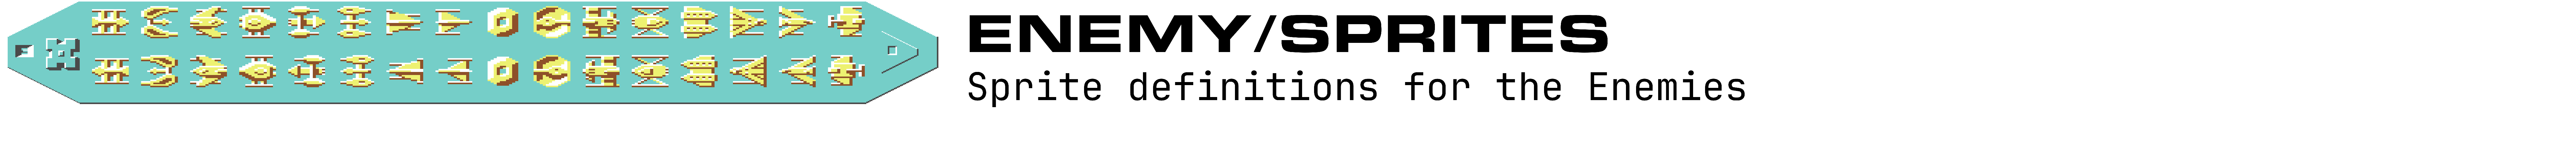

In [140]:
#### from PIL import Image, ImageFont,ImageDraw
"""
game_logic 3263
game_data 3204
structure_data 1896
game_logic 946
level_data 8196
surface1_charset 1024
surface2_charset 1024
surface3_charset 1024
game_logic 139
dropship_sprites 768
explosion_sprites 3328
ship_sprites 3062
enemy_sprites 2048
charset 3072
game_logic 384
"""

SEGMENT_NUMBER = 12

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 7
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (5750,200), mask=back1_png)
img.paste(back2_png, (5760,270), mask=back2_png)

"""
Draw the label
"""
label_text = "ENEMY/SPRITES"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((6300, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Sprite definitions for the Enemies
""").strip()
draw = ImageDraw.Draw(img)
draw.text((6300, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the sprites
"""
from itertools import chain
x,y = 600,40
x_orig = x
for i,f in enumerate(enemy_sprites):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f)
    decor_png = decor_png.resize((int(decor_png.width * 10), int(decor_png.height * 10)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if i+1 > 1 and (i+1) % 16 == 0:
        y+= 320
        x = 600
        continue
    x+=320
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/enemy_sprites.png")
img

### Charset

In [141]:
charset = """text_character_set_diagrams/base_character_sets/c64_white_00.png
text_character_set_diagrams/base_character_sets/c64_white_01.png
text_character_set_diagrams/base_character_sets/c64_white_02.png
text_character_set_diagrams/base_character_sets/c64_white_03.png
text_character_set_diagrams/base_character_sets/c64_white_04.png
text_character_set_diagrams/base_character_sets/c64_white_05.png
text_character_set_diagrams/base_character_sets/c64_white_06.png
text_character_set_diagrams/base_character_sets/c64_white_07.png
text_character_set_diagrams/base_character_sets/c64_white_08.png
text_character_set_diagrams/base_character_sets/c64_white_09.png
text_character_set_diagrams/base_character_sets/c64_white_0A.png
text_character_set_diagrams/base_character_sets/c64_white_0B.png
text_character_set_diagrams/base_character_sets/c64_white_0C.png
text_character_set_diagrams/base_character_sets/c64_white_0D.png
text_character_set_diagrams/base_character_sets/c64_white_0E.png
text_character_set_diagrams/base_character_sets/c64_white_0F.png
text_character_set_diagrams/base_character_sets/c64_white_10.png
text_character_set_diagrams/base_character_sets/c64_white_11.png
text_character_set_diagrams/base_character_sets/c64_white_12.png
text_character_set_diagrams/base_character_sets/c64_white_13.png
text_character_set_diagrams/base_character_sets/c64_white_14.png
text_character_set_diagrams/base_character_sets/c64_white_15.png
text_character_set_diagrams/base_character_sets/c64_white_16.png
text_character_set_diagrams/base_character_sets/c64_white_17.png
text_character_set_diagrams/base_character_sets/c64_white_18.png
text_character_set_diagrams/base_character_sets/c64_white_19.png
text_character_set_diagrams/base_character_sets/c64_white_1A.png
text_character_set_diagrams/base_character_sets/c64_white_1B.png
text_character_set_diagrams/base_character_sets/c64_white_1C.png
text_character_set_diagrams/base_character_sets/c64_white_1D.png
text_character_set_diagrams/base_character_sets/c64_white_1E.png
text_character_set_diagrams/base_character_sets/c64_white_1F.png
text_character_set_diagrams/base_character_sets/c64_white_20.png
text_character_set_diagrams/base_character_sets/c64_white_21.png
text_character_set_diagrams/base_character_sets/c64_white_22.png
text_character_set_diagrams/base_character_sets/c64_white_23.png
text_character_set_diagrams/base_character_sets/c64_white_24.png
text_character_set_diagrams/base_character_sets/c64_white_25.png
text_character_set_diagrams/base_character_sets/c64_white_26.png
text_character_set_diagrams/base_character_sets/c64_white_27.png
text_character_set_diagrams/base_character_sets/c64_white_28.png
text_character_set_diagrams/base_character_sets/c64_white_29.png
text_character_set_diagrams/base_character_sets/c64_white_2A.png
text_character_set_diagrams/base_character_sets/c64_white_2B.png
text_character_set_diagrams/base_character_sets/c64_white_2C.png
text_character_set_diagrams/base_character_sets/c64_white_2D.png
text_character_set_diagrams/base_character_sets/c64_white_2E.png
text_character_set_diagrams/base_character_sets/c64_white_2F.png
text_character_set_diagrams/base_character_sets/c64_white_3A.png
text_character_set_diagrams/base_character_sets/c64_white_3B.png
text_character_set_diagrams/base_character_sets/c64_white_3C.png
text_character_set_diagrams/base_character_sets/c64_white_3D.png
text_character_set_diagrams/base_character_sets/c64_white_3E.png
text_character_set_diagrams/base_character_sets/c64_white_3F.png
text_character_set_diagrams/base_character_sets/c64_white_40.png
text_character_set_diagrams/base_character_sets/c64_white_41.png
text_character_set_diagrams/base_character_sets/c64_white_42.png
text_character_set_diagrams/base_character_sets/c64_white_43.png
text_character_set_diagrams/base_character_sets/c64_white_44.png
text_character_set_diagrams/base_character_sets/c64_white_45.png
text_character_set_diagrams/base_character_sets/c64_white_46.png
text_character_set_diagrams/base_character_sets/c64_white_47.png
text_character_set_diagrams/base_character_sets/c64_white_48.png
text_character_set_diagrams/base_character_sets/c64_white_49.png
text_character_set_diagrams/base_character_sets/c64_white_4A.png
text_character_set_diagrams/base_character_sets/c64_white_4B.png
text_character_set_diagrams/base_character_sets/c64_white_4C.png
text_character_set_diagrams/base_character_sets/c64_white_4D.png
text_character_set_diagrams/base_character_sets/c64_white_4E.png
text_character_set_diagrams/base_character_sets/c64_white_4F.png
text_character_set_diagrams/base_character_sets/c64_white_50.png
text_character_set_diagrams/base_character_sets/c64_white_51.png
text_character_set_diagrams/base_character_sets/c64_white_52.png
text_character_set_diagrams/base_character_sets/c64_white_53.png
text_character_set_diagrams/base_character_sets/c64_white_54.png
text_character_set_diagrams/base_character_sets/c64_white_55.png
text_character_set_diagrams/base_character_sets/c64_white_56.png
text_character_set_diagrams/base_character_sets/c64_white_57.png
text_character_set_diagrams/base_character_sets/c64_white_58.png
text_character_set_diagrams/base_character_sets/c64_white_59.png
text_character_set_diagrams/base_character_sets/c64_white_5A.png
text_character_set_diagrams/base_character_sets/c64_white_5B.png
text_character_set_diagrams/base_character_sets/c64_white_5C.png
text_character_set_diagrams/base_character_sets/c64_white_5D.png
text_character_set_diagrams/base_character_sets/c64_white_5E.png
text_character_set_diagrams/base_character_sets/c64_white_5F.png
text_character_set_diagrams/base_character_sets/c64_white_60.png
text_character_set_diagrams/base_character_sets/c64_white_61.png
text_character_set_diagrams/base_character_sets/c64_white_62.png
text_character_set_diagrams/base_character_sets/c64_white_63.png
text_character_set_diagrams/base_character_sets/c64_white_64.png
text_character_set_diagrams/base_character_sets/c64_white_65.png
text_character_set_diagrams/base_character_sets/c64_white_66.png
text_character_set_diagrams/base_character_sets/c64_white_67.png
text_character_set_diagrams/base_character_sets/c64_white_68.png
text_character_set_diagrams/base_character_sets/c64_white_69.png
text_character_set_diagrams/base_character_sets/c64_white_6A.png
text_character_set_diagrams/base_character_sets/c64_white_6B.png
text_character_set_diagrams/base_character_sets/c64_white_6C.png
text_character_set_diagrams/base_character_sets/c64_white_6D.png
text_character_set_diagrams/base_character_sets/c64_white_6E.png
text_character_set_diagrams/base_character_sets/c64_white_6F.png
text_character_set_diagrams/base_character_sets/c64_white_70.png
text_character_set_diagrams/base_character_sets/c64_white_71.png
text_character_set_diagrams/base_character_sets/c64_white_72.png
text_character_set_diagrams/base_character_sets/c64_white_73.png
text_character_set_diagrams/base_character_sets/c64_white_74.png
text_character_set_diagrams/base_character_sets/c64_white_75.png
text_character_set_diagrams/base_character_sets/c64_white_76.png
text_character_set_diagrams/base_character_sets/c64_white_77.png
text_character_set_diagrams/base_character_sets/c64_white_78.png
text_character_set_diagrams/base_character_sets/c64_white_79.png
text_character_set_diagrams/base_character_sets/c64_white_7A.png
text_character_set_diagrams/base_character_sets/c64_white_7B.png
text_character_set_diagrams/base_character_sets/c64_white_7C.png
text_character_set_diagrams/base_character_sets/c64_white_7D.png
text_character_set_diagrams/base_character_sets/c64_white_7E.png
text_character_set_diagrams/base_character_sets/c64_white_7F.png
""".split('\n')[:-1]

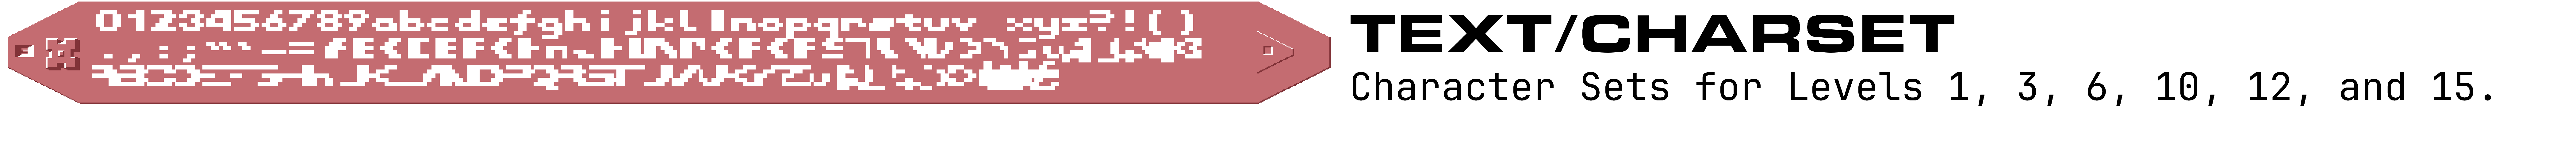

In [142]:
from PIL import Image, ImageFont,ImageDraw

SEGMENT_NUMBER = 13

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 15
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

for i in range(0, num_lines):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add surface decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (8200,200), mask=back1_png)
img.paste(back2_png, (8210,270), mask=back2_png)

"""
Draw the label
"""
label_text = "TEXT/CHARSET"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((8800, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
level_charsets = [2,0,2,0,1,2,1,0,1,2,0,2,1,0,2]
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Character Sets for Levels 1, 3, 6, 10, 12, and 15.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((8800, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
from itertools import chain
x,y = 600,40
x_orig = x
for i,f in enumerate(charset):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f)
    decor_png = decor_png.resize((int(decor_png.width * 1.8), int(decor_png.height * 1.8)), Image.NEAREST)
    img.paste(decor_png, (x,y), mask=decor_png)
    if i+1 > 0 and (i+1) % 40 == 0:
        y+= 180
        x = 600
        continue
    x+=180
    
img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/text_charset.png")
img

# Scratchpad

In [8]:
from PIL import Image

LINE_HEIGHT = 680
WIDTH = 40 * 560
HEIGHT = (LINE_HEIGHT + 300) * 16
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

level = -1
BYTES_PER_LINE =16
x,y = 0,0
for segment_name,segment_bytes in segments:
    print(segment_name)
    segment_len =  len(segment_bytes)
    num_lines = int(segment_len/BYTES_PER_LINE)

    level = segment_colors[segment_name]
    open_segment0_png = Image.open(f"surface_structures/{level+1}_138.png")
    open_segment_png = Image.open(f"surface_structures/{level+1}_4.png")
    close_segment0_png = Image.open(f"surface_structures/{level+1}_139.png")
    close_segment_png = Image.open(f"surface_structures/{level+1}_6.png")
    open_line_png = Image.open(f"surface_structures/{level+1}_1.png")
    close_line_png = Image.open(f"surface_structures/{level+1}_3.png")
    mid_line0_png = Image.open(f"surface_structures/{level+1}_2.png")
    mid_line_png = Image.open(f"surface_structures/{level+1}_5.png")
    connector_png = Image.open(f"surface_structures/{level+1}_13.png")
    connector2_png = Image.open(f"surface_structures/{level+1}_14.png")
    
    x += open_segment0_png.width
    img.paste(open_segment_png, (x,y), mask=open_segment_png)
    img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
    x += open_segment_png.width

    for i in range(0, num_lines,3):
        img.paste(mid_line_png, (x,y), mask=mid_line_png)
        x += mid_line_png.width

    img.paste(close_segment_png, (x,y), mask=close_segment_png)
    x += close_segment_png.width
    x-=40
    img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
    x += close_segment0_png.width

    x = 0
    y += mid_line_png.height + 300

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("source_map/main_map.png")
img

game_logic
game_data
structure_data
game_logic
level_data
surface1_charset
surface2_charset
surface3_charset
game_logic
dropship_sprites
explosion_sprites
ship_sprites
enemy_sprites
charset
game_logic


In [113]:
17179869184/47000

365529.1315744681

In [114]:
 1099511627776/47000

23393864.42076596